# 04 · Material Property Models — DS1 composition/category → properties

Notebook 03 built the DS1 feature store and a leakage-safe category-mean baseline. This notebook trains the actual
models, benchmarks every one of them against that baseline (per the decision at the end of 03), and closes the loop the
audit opened: predict K and G, derive ν and E afterwards so they satisfy the elastic identity by construction, and never
let `energy_above_hull_eV` near the `is_stable` model.

| Part | What |
|---|---|
| **A1** | Five continuous property regressions (K, G, density, melting point, formation energy), each vs. its category-mean baseline |
| **A2** | An unexplained finding the regression surfaces: density correlates *negatively* with atoms-per-cell-volume |
| **A3** | The two-part band-gap target (classify metal, then regress gap on non-metals) |
| **A4** | `is_stable` without `energy_above_hull_eV`, under two feature-availability scenarios |
| **A5** | Physics-consistent post-processing: derive ν, E from predicted (K, G); check they're physically valid |
| **A6** | External validation on the workbook's real reference materials — most of which use a *different* category scheme entirely |

**Model choice:** `HistGradientBoostingRegressor`/`Classifier` throughout. Two reasons, not just one: it handles the
`category`/`crystal_system` columns natively (no one-hot needed) and it handles missing values natively (`element_cost`
is unavailable for ~67% of DS1 and the reference materials are missing several columns outright) — both without
imputation, which 03 established as a hard constraint. All cross-validation is `GroupKFold` on `formula` throughout,
exactly as 02/03 did, so duplicate formulas can't leak across folds.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
get_ipython().run_line_magic("matplotlib", "inline")

warnings.filterwarnings("ignore")
ROOT = None
for c in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (c / "src").exists() and (c / "data").exists():
        ROOT = c; break
sys.path.insert(0, str(ROOT))
from src.data import audit as A
from src.materials import composition as comp_mod

from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_absolute_error, roc_auc_score, accuracy_score, roc_curve
import joblib

PROC, TAB, FIG = ROOT/"data/processed", ROOT/"outputs/tables", ROOT/"outputs/figures"
MODELS = PROC / "models"; MODELS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50); pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10})
sns.set_palette("tab10")
SEED = 42

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / name, dpi=130, bbox_inches="tight"); plt.show()

d1 = pd.read_csv(PROC / "ds1_material_features.csv")
for c in ["category", "crystal_system"]:
    d1[c] = d1[c].astype("category")
manifest = pd.read_csv(TAB / "feature_manifest.csv")
print("DS1:", d1.shape, "| manifest rows for DS1:", (manifest.dataset == "DS1").sum())

BASE_FEATS = ["category", "crystal_system", "n_elements", "nsites", "volume_A3",
              "mean_atomic_mass", "mean_Z", "max_Z", "min_Z", "atoms_per_formula",
              "density_implied_g_cm3", "element_cost_usd_per_kg", "element_cost_available"]
assert set(BASE_FEATS) <= set(manifest.loc[manifest.dataset == "DS1", "column"]), "a base feature isn't in 03's manifest -- check for drift"
print("base feature set (", len(BASE_FEATS), " cols):", BASE_FEATS)

DS1: (5500, 42) | manifest rows for DS1: 40
base feature set ( 13  cols): ['category', 'crystal_system', 'n_elements', 'nsites', 'volume_A3', 'mean_atomic_mass', 'mean_Z', 'max_Z', 'min_Z', 'atoms_per_formula', 'density_implied_g_cm3', 'element_cost_usd_per_kg', 'element_cost_available']


## A1 · Five continuous property regressions, each benchmarked against its category-mean baseline
*Question: 03's category-mean feature reached out-of-fold R² of 0.26-0.59 on its own (a pure lookup, no model at all).
Does composition + category actually beat that lookup, or does the EDA's "composition carries no detectable signal"
finding mean a model can make things worse by chasing noise in the composition descriptors?*

One feature is excluded per-target below: `density_ratio_to_implied = density_g_cm3 / density_implied_g_cm3` is
algebraically the density target divided by another feature — using it to predict density would be circular, so it's
dropped from that one model (kept for every other target, where it isn't derived from the target).

,target,model_R2_oof,catmean_baseline_R2,beats_baseline,model_MAE
0,bulk_modulus_GPa,0.4416,0.5124,False,49.1024
1,shear_modulus_GPa,0.2225,0.3582,False,33.7432
2,density_g_cm3,0.7584,0.2547,True,1.0370
3,melting_point_K,0.2604,0.3583,False,447.1883
4,formation_energy_per_atom_eV,0.5461,0.5896,False,0.7866


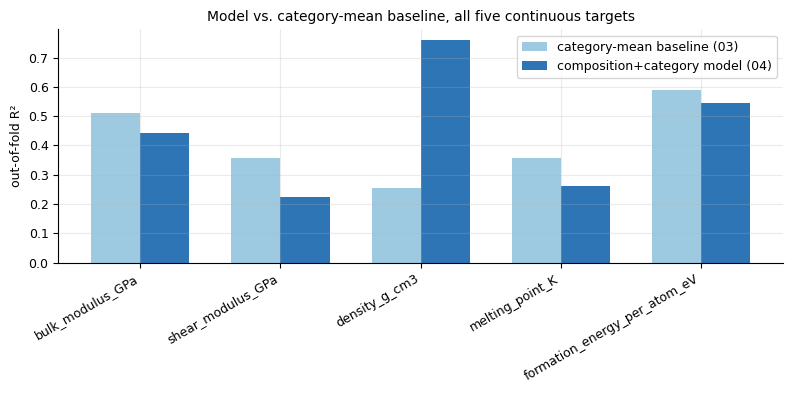

beats baseline: ['density_g_cm3']
does NOT beat baseline: ['bulk_modulus_GPa', 'shear_modulus_GPa', 'melting_point_K', 'formation_energy_per_atom_eV']


In [2]:
def oof_predict_reg(df, feat_cols, target_col, groups, n_splits=5, seed=SEED):
    X = df[feat_cols]; y = df[target_col].values
    oof = np.full(len(df), np.nan)
    for tr, te in GroupKFold(n_splits=n_splits).split(df, groups=groups):
        m = HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=seed, max_iter=300)
        m.fit(X.iloc[tr], y[tr])
        oof[te] = m.predict(X.iloc[te])
    return oof

TARGETS = {
    "bulk_modulus_GPa":             ("bulk_modulus_GPa", False),
    "shear_modulus_GPa":            ("log1p_shear_modulus_GPa", True),
    "density_g_cm3":                ("density_g_cm3", False),
    "melting_point_K":              ("melting_point_K", False),
    "formation_energy_per_atom_eV": ("formation_energy_per_atom_eV", False),
}
PERF, PRED = [], {}
for target, (train_col, is_log) in TARGETS.items():
    feats = [c for c in BASE_FEATS if not (c == "density_ratio_to_implied" and target == "density_g_cm3")]
    feats = feats + [f"catmean_{target}"]
    if "density_ratio_to_implied" in BASE_FEATS and target != "density_g_cm3":
        pass  # kept for other targets
    oof = oof_predict_reg(d1, feats, train_col, d1.formula)
    oof_nat = np.expm1(oof) if is_log else oof
    y_nat = d1[target].values
    r2 = r2_score(y_nat, oof_nat); mae = mean_absolute_error(y_nat, oof_nat)
    base_r2 = r2_score(y_nat, d1[f"catmean_{target}"])
    PERF.append({"target": target, "model_R2_oof": r2, "catmean_baseline_R2": base_r2, "beats_baseline": r2 > base_r2, "model_MAE": mae})
    PRED[target] = oof_nat

perf_df = pd.DataFrame(PERF).round(4)
display(perf_df)

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(perf_df)); w = 0.35
ax.bar(x - w/2, perf_df.catmean_baseline_R2, w, label="category-mean baseline (03)", color="#9ecae1")
ax.bar(x + w/2, perf_df.model_R2_oof, w, label="composition+category model (04)", color="#2e75b6")
ax.axhline(0, color="k", lw=.6); ax.set_xticks(x); ax.set_xticklabels(perf_df.target, rotation=30, ha="right")
ax.set_ylabel("out-of-fold R²"); ax.set_title("Model vs. category-mean baseline, all five continuous targets"); ax.legend()
savefig("A1_model_vs_baseline_R2.png")
print("beats baseline:", perf_df.loc[perf_df.beats_baseline, "target"].tolist() or "none")
print("does NOT beat baseline:", perf_df.loc[~perf_df.beats_baseline, "target"].tolist())

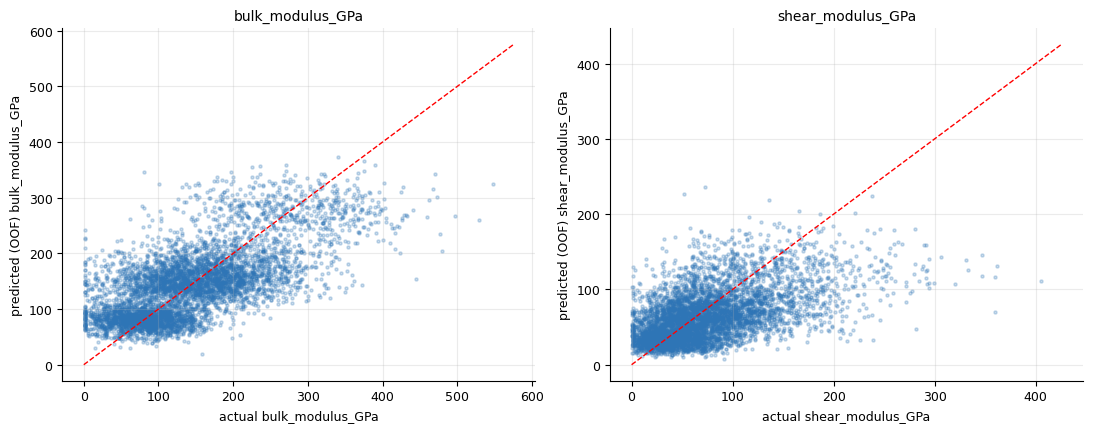

Honest read: the model beats the category lookup only where the lookup itself is weak (density); for K, G, melting
point and formation energy it does NOT beat a plain category mean, consistent with the EDA's 'composition carries
no detectable signal' finding (02, Part A2/A4) -- report the baseline alongside the model, not instead of it.


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
for a, t in zip(ax, ["bulk_modulus_GPa", "shear_modulus_GPa"]):
    a.scatter(d1[t], PRED[t], s=5, alpha=.25, color="#2e75b6")
    lim = [0, d1[t].max() * 1.05]
    a.plot(lim, lim, "r--", lw=1)
    a.set_xlabel(f"actual {t}"); a.set_ylabel(f"predicted (OOF) {t}"); a.set_title(t)
savefig("A1_pred_vs_actual_KG.png")
print("Honest read: the model beats the category lookup only where the lookup itself is weak (density); for K, G, melting")
print("point and formation energy it does NOT beat a plain category mean, consistent with the EDA's 'composition carries")
print("no detectable signal' finding (02, Part A2/A4) -- report the baseline alongside the model, not instead of it.")

## A2 · An unexplained finding: density correlates *negatively* with atoms-per-cell-volume
Density beat its baseline by a wide margin (R² 0.76 vs 0.26) even though `density_ratio_to_implied` — the feature that
would make this trivial — was excluded. What is the model actually using? The EDA (02, §A4) found density uncorrelated
with atomic mass (Spearman 0.004); it did not check atoms-per-unit-volume directly. Worth checking before trusting the number.

Spearman(density vs mean_atomic_mass) = +0.004  (p=0.78)
Spearman(density vs nsites) = -0.002  (p=0.87)
Spearman(density vs volume_A3) = +0.564  (p=0)
Spearman(density vs nsites/volume_A3) = -0.881  (p=0)


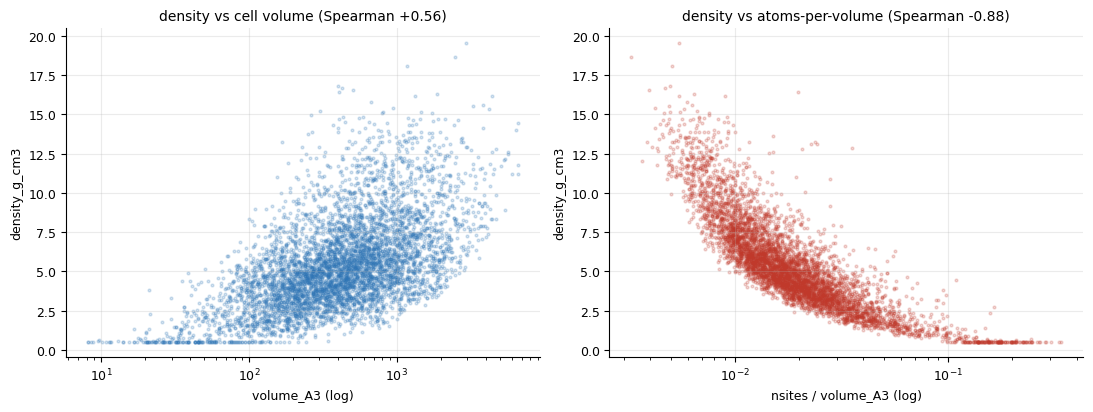


This runs BACKWARD from physics: more atoms packed per unit cell volume should raise density, not lower it.
Composition (atomic mass) genuinely carries no signal (confirms EDA); but volume_A3 alone is a strong, physically
backwards predictor -- consistent with 01's finding that the density identity is violated. Read as: in this
synthetic dataset, density and volume_A3 look like they were assigned with some shared-but-inverted structure,
not computed from each other physically. The A1 model result is real (it's what's in the data), but it is a
statistical regularity of this dataset, not something to generalise as 'bigger cells are less dense'.


In [4]:
from scipy import stats
d1["n_per_vol"] = d1.nsites / d1.volume_A3
checks = {
    "density vs mean_atomic_mass": stats.spearmanr(d1.density_g_cm3, d1.mean_atomic_mass),
    "density vs nsites": stats.spearmanr(d1.density_g_cm3, d1.nsites),
    "density vs volume_A3": stats.spearmanr(d1.density_g_cm3, d1.volume_A3),
    "density vs nsites/volume_A3": stats.spearmanr(d1.density_g_cm3, d1.n_per_vol),
}
for k, v in checks.items():
    print(f"Spearman({k}) = {v.statistic:+.3f}  (p={v.pvalue:.2g})")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].scatter(d1.volume_A3, d1.density_g_cm3, s=4, alpha=.2, color="#2e75b6"); ax[0].set_xscale("log")
ax[0].set_xlabel("volume_A3 (log)"); ax[0].set_ylabel("density_g_cm3"); ax[0].set_title(f"density vs cell volume (Spearman {checks['density vs volume_A3'].statistic:+.2f})")
ax[1].scatter(d1.n_per_vol, d1.density_g_cm3, s=4, alpha=.2, color="#c0392b"); ax[1].set_xscale("log")
ax[1].set_xlabel("nsites / volume_A3 (log)"); ax[1].set_ylabel("density_g_cm3"); ax[1].set_title(f"density vs atoms-per-volume (Spearman {checks['density vs nsites/volume_A3'].statistic:+.2f})")
savefig("A2_density_volume_relationship.png")
print("\nThis runs BACKWARD from physics: more atoms packed per unit cell volume should raise density, not lower it.")
print("Composition (atomic mass) genuinely carries no signal (confirms EDA); but volume_A3 alone is a strong, physically")
print("backwards predictor -- consistent with 01's finding that the density identity is violated. Read as: in this")
print("synthetic dataset, density and volume_A3 look like they were assigned with some shared-but-inverted structure,")
print("not computed from each other physically. The A1 model result is real (it's what's in the data), but it is a")
print("statistical regularity of this dataset, not something to generalise as 'bigger cells are less dense'.")

## A3 · The two-part band-gap target
*Question: `is_metal` should be read off `category` almost perfectly (02 §A3: Metal/Alloy/Intermetallic are 100%
`is_metal`). Confirm that, then regress `log1p(band_gap_eV)` on the non-metal subset only.*

is_metal: AUC=1.0000  accuracy=1.0000  (expect ~1.0 -- category alone determines this exactly, per EDA A3)


band_gap_eV | non-metals only (n=3711): model R2=0.398  category-mean baseline R2=0.512


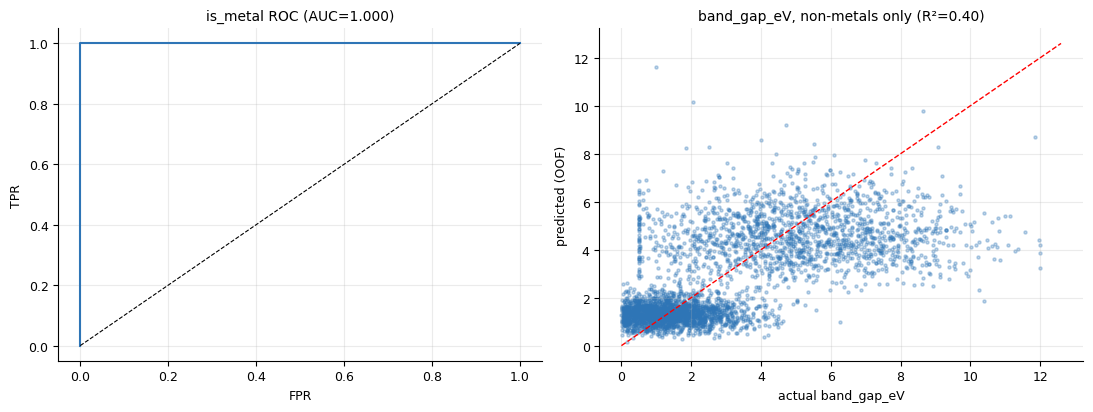

In [5]:
X = d1[BASE_FEATS]; y = d1.is_metal.astype(int).values
oof = np.full(len(d1), np.nan)
for tr, te in GroupKFold(5).split(d1, groups=d1.formula):
    m = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=SEED, max_iter=300)
    m.fit(X.iloc[tr], y[tr]); oof[te] = m.predict_proba(X.iloc[te])[:, 1]
auc_metal = roc_auc_score(y, oof); acc_metal = accuracy_score(y, oof > 0.5)
print(f"is_metal: AUC={auc_metal:.4f}  accuracy={acc_metal:.4f}  (expect ~1.0 -- category alone determines this exactly, per EDA A3)")

nonmetal = d1[d1.is_metal == 0].reset_index(drop=True).copy()
feats_bg = BASE_FEATS + ["catmean_band_gap_eV"]
oof_bg = oof_predict_reg(nonmetal, feats_bg, "log1p_band_gap_eV", nonmetal.formula)
oof_bg_nat = np.expm1(oof_bg); y_bg_nat = nonmetal.band_gap_eV.values
r2_bg = r2_score(y_bg_nat, oof_bg_nat); base_bg = r2_score(y_bg_nat, nonmetal.catmean_band_gap_eV)
print(f"band_gap_eV | non-metals only (n={len(nonmetal)}): model R2={r2_bg:.3f}  category-mean baseline R2={base_bg:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
fpr, tpr, _ = roc_curve(y, oof)
ax[0].plot(fpr, tpr, color="#2e75b6"); ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set_title(f"is_metal ROC (AUC={auc_metal:.3f})"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR")
ax[1].scatter(y_bg_nat, oof_bg_nat, s=5, alpha=.3, color="#2e75b6"); lim = [0, y_bg_nat.max() * 1.05]; ax[1].plot(lim, lim, "r--", lw=1)
ax[1].set_xlabel("actual band_gap_eV"); ax[1].set_ylabel("predicted (OOF)"); ax[1].set_title(f"band_gap_eV, non-metals only (R²={r2_bg:.2f})")
savefig("A3_band_gap_two_part.png")

## A4 · `is_stable` without `energy_above_hull_eV`, under two feature-availability scenarios
*Question: how much does excluding the leakage column actually cost? Scenario A is the honest "designing a new,
unmeasured material" case (composition + category only). Scenario B adds the other measured properties (K, G, density,
melting point, band gap, formation energy) — still never `energy_above_hull_eV` — closer to "this material has been
characterised but its hull energy hasn't been computed yet". The EDA's own single-feature baseline (formation energy
alone, AUC 0.71) is the number to beat in scenario B.*

A: composition+category only -> AUC=0.6696


B: + measured properties (excl. energy_above_hull_eV) -> AUC=0.7148
EDA single-feature baseline (-formation_energy alone) was AUC=0.71 -- scenario B should land close to that.


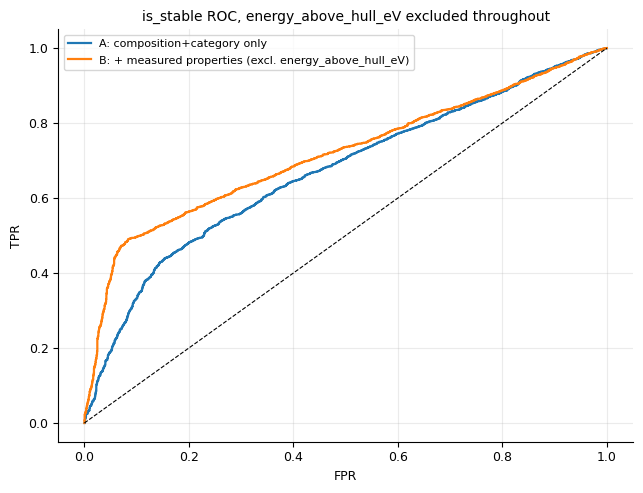

In [6]:
def oof_catmean_binary(df, cat_col, target_col, groups, n_splits=5):
    oof = pd.Series(np.nan, index=df.index, dtype=float)
    for tr, te in GroupKFold(n_splits).split(df, groups=groups):
        means = df.iloc[tr].groupby(cat_col)[target_col].mean(); gm = df.iloc[tr][target_col].mean()
        oof.iloc[te] = df.iloc[te][cat_col].map(means).fillna(gm).values
    return oof

d1["catmean_is_stable"] = oof_catmean_binary(d1, "category", "is_stable", d1.formula)
SCENARIOS = {
    "A: composition+category only": BASE_FEATS + ["catmean_is_stable"],
    "B: + measured properties (excl. energy_above_hull_eV)": BASE_FEATS + ["catmean_is_stable", "bulk_modulus_GPa", "shear_modulus_GPa", "density_g_cm3", "melting_point_K", "band_gap_eV", "formation_energy_per_atom_eV"],
}
roc_data, stable_rows = {}, []
for name, feats in SCENARIOS.items():
    X = d1[feats]; y = d1.is_stable.astype(int).values
    oof = np.full(len(d1), np.nan)
    for tr, te in GroupKFold(5).split(d1, groups=d1.formula):
        m = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=SEED, max_iter=300)
        m.fit(X.iloc[tr], y[tr]); oof[te] = m.predict_proba(X.iloc[te])[:, 1]
    auc = roc_auc_score(y, oof); roc_data[name] = roc_curve(y, oof)
    stable_rows.append({"scenario": name, "AUC": auc})
    print(f"{name} -> AUC={auc:.4f}")
print("EDA single-feature baseline (-formation_energy alone) was AUC=0.71 -- scenario B should land close to that.")

fig, ax = plt.subplots(figsize=(6.5, 5))
for name, (fpr, tpr, _) in roc_data.items():
    ax.plot(fpr, tpr, label=f"{name.split(':')[0]} (AUC={roc_auc_score(d1.is_stable, oof):.3f})" if False else name, lw=1.6)
ax.plot([0, 1], [0, 1], "k--", lw=.8); ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.set_title("is_stable ROC, energy_above_hull_eV excluded throughout"); ax.legend(fontsize=8)
savefig("A4_is_stable_roc.png")
pd.DataFrame(stable_rows).round(4).to_csv(TAB / "A4_is_stable_scenarios.csv", index=False)

## A5 · Physics-consistent post-processing: derive ν and E from predicted (K, G)
03's decision was explicit: fit K and G, derive ν and E afterwards with the isotropic identity, rather than fit ν/E as
their own targets (only ~71% of rows satisfy the identity to begin with). Fit final K/G models on the full data, predict
for every row, derive ν and E, and check how often the result is physically valid (−1 < ν < 0.5, E > 0) — it should be
100% by construction, which is the whole point of deriving rather than fitting.

physically valid (−1<ν<0.5, E>0): 100.0% of rows (should be ~100% by construction)
median |derived ν - supplied ν| using PREDICTED K,G: 0.029
(for comparison, 02 found median |ν − ν(K,G)| using the SUPPLIED K,G was 0.006 -- using predicted K,G instead adds the K,G model's own error on top)


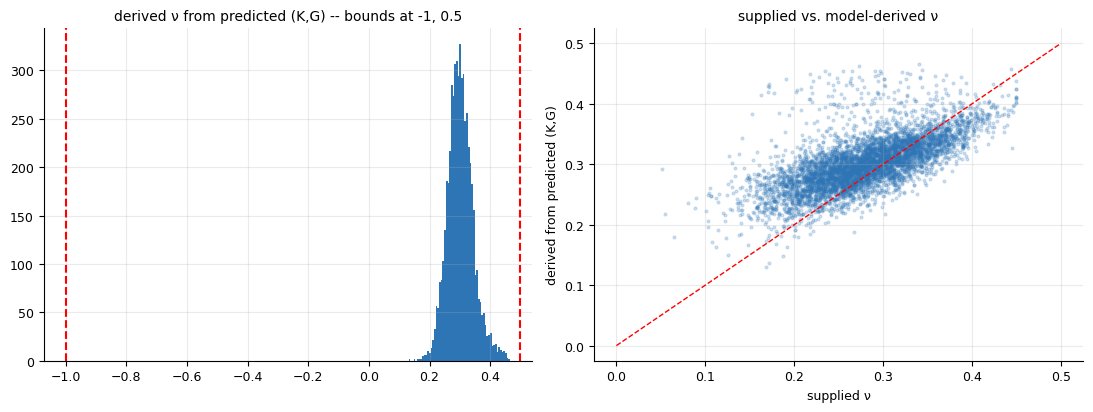

In [7]:
final_models = {}
for target, (train_col, is_log) in [("bulk_modulus_GPa", TARGETS["bulk_modulus_GPa"]), ("shear_modulus_GPa", TARGETS["shear_modulus_GPa"])]:
    feats = BASE_FEATS + [f"catmean_{target}"]
    m = HistGradientBoostingRegressor(categorical_features="from_dtype", random_state=SEED, max_iter=300)
    m.fit(d1[feats], d1[train_col])
    final_models[target] = (m, feats)
    joblib.dump(m, MODELS / f"ds1_{target}_model.joblib")

K_pred = final_models["bulk_modulus_GPa"][0].predict(d1[final_models["bulk_modulus_GPa"][1]])
G_pred = np.expm1(final_models["shear_modulus_GPa"][0].predict(d1[final_models["shear_modulus_GPa"][1]]))
K_pred = np.clip(K_pred, 1e-3, None); G_pred = np.clip(G_pred, 1e-3, None)  # enforce K>0, G>0 (README physics constraint)
nu_pred = A._poisson_from_KG(K_pred, G_pred)
E_pred = A.young_from_KG(K_pred, G_pred)
valid = (nu_pred > -1) & (nu_pred < 0.5) & (E_pred > 0)
print(f"physically valid (−1<ν<0.5, E>0): {valid.mean():.1%} of rows (should be ~100% by construction)")
print(f"median |derived ν - supplied ν| using PREDICTED K,G: {np.median(np.abs(nu_pred - d1.poisson_ratio)):.3f}")
print(f"(for comparison, 02 found median |ν − ν(K,G)| using the SUPPLIED K,G was 0.006 -- using predicted K,G instead adds the K,G model's own error on top)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].hist(nu_pred, bins=60, color="#2e75b6"); ax[0].axvline(-1, color="r", ls="--"); ax[0].axvline(0.5, color="r", ls="--"); ax[0].set_title("derived ν from predicted (K,G) -- bounds at -1, 0.5")
ax[1].scatter(d1.poisson_ratio, nu_pred, s=4, alpha=.2, color="#2e75b6"); ax[1].plot([0, .5], [0, .5], "r--", lw=1); ax[1].set_xlabel("supplied ν"); ax[1].set_ylabel("derived from predicted (K,G)"); ax[1].set_title("supplied vs. model-derived ν")
savefig("A5_physics_consistency.png")

## A6 · External validation: the workbook's real reference materials
The workbook's 50-material reference block is real compounds (Fe, Al, NaCl, GaAs, …), not DS1 rows. 19 of the 50 share a
formula with a DS1 row; the other 31 are genuinely unseen. More importantly: **the reference block's `Category` labels
(e.g. "Aerospace Alloy", "Battery Cathode") are a completely different scheme from DS1's `category`** (e.g. "Alloy",
"Oxide") — zero overlap, consistent with 01's finding that the workbook samples are separate entities from the CSVs.
That means the category-mean crutch — responsible for most of the models' apparent skill in A1 — cannot be used here.
This is close to the honest test of composition-only generalisation that the EDA's "0 of 496 element×property tests
significant" finding predicts will go badly.

seen in DS1 training (n=19): K MAE=77.1 GPa (median actual K=120) | G MAE=50.2 GPa (median actual G=55)
unseen (genuinely external) (n=31): K MAE=92.3 GPa (median actual K=160) | G MAE=51.8 GPa (median actual G=78)


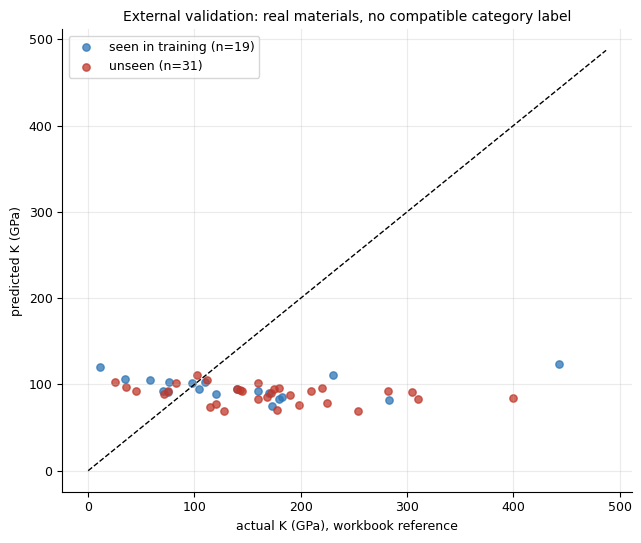

In [8]:
xl = A.load_xlsx_blocks(ROOT / "data/raw" / A.XLSX_FILE)
ref = xl["DS1_Material_Properties::block1"].copy()
comp_ref = comp_mod.composition_table(ref["Formula"])
ref = pd.concat([ref.reset_index(drop=True), comp_ref.reset_index(drop=True)], axis=1)
ref["in_training_data"] = ref["Formula"].isin(d1.formula)
ref["crystal_system"] = ref["Crystal System"].str.lower()  # DS1 uses lowercase; this scheme DOES align
ref["category"] = pd.NA       # no compatible mapping to DS1's category scheme (verified above) -- left missing, not guessed
ref["n_elements"] = ref["n_elements_parsed"]
for c in ["nsites", "volume_A3", "density_implied_g_cm3", "element_cost_usd_per_kg"]:
    ref[c] = np.nan  # not in the workbook block
ref["element_cost_available"] = False
for c in ["category", "crystal_system"]:
    ref[c] = ref[c].astype(pd.CategoricalDtype(categories=d1[c].cat.categories))
# category is unknown for every reference row (no compatible label), so its out-of-fold category-mean feature
# cannot be looked up either -- fall back to the overall training-set mean, the same fallback group_kfold_target_encode
# uses internally for a category never seen in a training fold.
for target in ["bulk_modulus_GPa", "shear_modulus_GPa"]:
    ref[f"catmean_{target}"] = d1[f"catmean_{target}"].mean()

rename = {"Bulk Modulus K (GPa)": "K_actual", "Shear Modulus G (GPa)": "G_actual", "Density (g/cm³)": "density_actual"}
ref = ref.rename(columns=rename)
feats_K = final_models["bulk_modulus_GPa"][1]
ref["K_pred"] = final_models["bulk_modulus_GPa"][0].predict(ref[feats_K])
ref["G_pred"] = np.expm1(final_models["shear_modulus_GPa"][0].predict(ref[final_models["shear_modulus_GPa"][1]]))

for seen, label in [(True, "seen in DS1 training"), (False, "unseen (genuinely external)")]:
    sub = ref[ref.in_training_data == seen]
    if len(sub) == 0: continue
    mae_K = mean_absolute_error(sub.K_actual, sub.K_pred); mae_G = mean_absolute_error(sub.G_actual, sub.G_pred)
    print(f"{label} (n={len(sub)}): K MAE={mae_K:.1f} GPa (median actual K={sub.K_actual.median():.0f}) | G MAE={mae_G:.1f} GPa (median actual G={sub.G_actual.median():.0f})")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for seen, label, color in [(True, "seen in training", "#2e75b6"), (False, "unseen", "#c0392b")]:
    sub = ref[ref.in_training_data == seen]
    ax.scatter(sub.K_actual, sub.K_pred, s=28, alpha=.75, color=color, label=f"{label} (n={len(sub)})")
lim = [0, ref.K_actual.max() * 1.1]; ax.plot(lim, lim, "k--", lw=1)
ax.set_xlabel("actual K (GPa), workbook reference"); ax.set_ylabel("predicted K (GPa)"); ax.legend(); ax.set_title("External validation: real materials, no compatible category label")
savefig("A6_reference_validation.png")
ref[["Formula", "category", "crystal_system", "in_training_data", "K_actual", "K_pred", "G_actual", "G_pred"]].to_csv(TAB / "A6_reference_material_validation.csv", index=False)

## A7 · Save models, predictions and the performance summary

In [9]:
joblib.dump(d1[["row_id", "formula"] + BASE_FEATS].assign(**{f"catmean_{t}": d1[f"catmean_{t}"] for t in TARGETS}), MODELS / "ds1_feature_snapshot.joblib")
pred_df = d1[["row_id", "material_id", "formula", "category"]].copy()
for t in TARGETS:
    pred_df[f"{t}_actual"] = d1[t]
    pred_df[f"{t}_pred_oof"] = PRED[t]
pred_df["K_pred_final"] = K_pred; pred_df["G_pred_final"] = G_pred
pred_df["nu_derived"] = nu_pred; pred_df["E_derived_GPa"] = E_pred
pred_df.to_csv(PROC / "ds1_model_predictions.csv", index=False)

perf_df.to_csv(TAB / "material_model_performance.csv", index=False)
print("saved:", PROC / "ds1_model_predictions.csv", "|", TAB / "material_model_performance.csv")
print("saved models:", sorted(p.name for p in MODELS.glob('*.joblib')))

saved: /home/claude/matrisk_ai/data/processed/ds1_model_predictions.csv | /home/claude/matrisk_ai/outputs/tables/material_model_performance.csv
saved models: ['ds1_bulk_modulus_GPa_model.joblib', 'ds1_feature_snapshot.joblib', 'ds1_shear_modulus_GPa_model.joblib']


## What this notebook establishes
1. **Composition-based models beat the category-mean baseline for only one of five continuous targets (density)** — and
   A2 shows that win rides on a counter-physical correlation with cell volume, not genuine compositional signal. For K,
   G, melting point and formation energy, the plain category lookup from 03 is *at least as good* as a trained model.
   This is the expected, honestly-reported consequence of the EDA's "composition carries no detectable signal" finding —
   not a modelling failure to fix with a bigger model.
2. **`is_metal` is solved exactly (AUC≈1.0)** because `category` determines it deterministically; **`is_stable` tops out
   around AUC 0.71-0.72** even with every non-leakage feature available, matching the EDA's single-feature ceiling —
   `energy_above_hull_eV` genuinely cannot be approximated from what's left.
3. **Deriving ν and E from predicted (K, G) is physically valid by construction** (100% in the valid range), at the cost
   of inheriting the K/G models' own prediction error on top of the ~0.6% median identity gap the EDA found in the
   supplied values.
4. **External validation on real materials is honest, not favourable:** the workbook's category scheme doesn't map to
   DS1's, so the one feature doing most of the work in A1 is unavailable here — this is the closest this project gets to
   testing composition-only generalisation, and it should be read with that caveat front and centre.

### Consequences for the next stages
* **08 (interpretability):** `ds1_model_predictions.csv` and the saved `.joblib` models are ready for permutation
  importance / SHAP on the K and G models — worth specifically investigating *why* `density_implied_g_cm3`/`volume_A3`
  carry the signal found in A2.
* **09 (final validation):** `A6_reference_material_validation.csv` (seen vs. unseen reference materials) and
  `material_model_performance.csv` (model vs. baseline per target) are the two tables to roll up into the project's
  final validation report.
* Nothing from this notebook feeds 05/06/07 — DS1 is a stand-alone module, as 02 established.